# Single-class bird detector: YOLO26n plus a plain-Keras ESP32 continuation

This notebook builds a **full-scene**, single-class (`bird`) object detector from three
sources listed in `dataset_dirs.txt`:

1.
2. **ESP32 captures** — primary deployment domain, source of negatives, final validation/test,
   and LiteRT/TFLite representative calibration frames.
3. **CUB-200-2011** — authoritative localization boxes across many species and poses.
4. **iNaturalist** — provisional scored boxes plus a small, separately stored human-reviewed
   subset. Machine scores in the range 0.80–1.00 are useful for filtering and review, but
   **are not accepted as ground-truth annotations**.

Species labels are retained as metadata only. The detector always uses one class:
`0: bird`. The former Model Maker/EfficientDet section has been replaced by a plain-Keras continuation notebook.

## Safety and execution policy

* Detector inputs are original scenes. ESP32 `crop_path` values are never used.
* CUB official test images never enter training.
* iNaturalist `gt_select` images never enter training.
* ESP32 capture-day groups never cross train/validation/test boundaries.
* INT8 calibration uses ESP32 **training** frames only.
* Long-running phases are disabled by default. Run the manifest/audit sections first, inspect
  the summaries, then enable the required flags in the configuration cell.

The notebook is designed for the project's WSL workflow. Current Ultralytics exports use
`format="litert"`; the result is still a `.tflite` model suitable for Raspberry Pi LiteRT.

## 1. Configuration

The initial settings target an RTX 3060 Laptop GPU with 6 GB VRAM. YOLO starts at batch 16
and retries with batch 8 after a CUDA out-of-memory error. EfficientDet-Lite starts at batch 8
and retries at batch 4.

In [3]:
import os
from pathlib import Path

# Safe defaults: joining/auditing runs; expensive phases require explicit opt-in.
EXPORT_TRAINING_DATASETS = True
RUN_YOLO_TRAINING = True
RUN_YOLO_CHECKPOINT_SELECTION = True
RUN_YOLO_LITERT_EXPORT = True
RUN_FINAL_EVALUATION = True

QUICK_RUN = os.getenv("BIRD_DETECTOR_QUICK_RUN", "0") == "1"
VERIFY_ALL_IMAGE_FILES = not QUICK_RUN

SEED = 1234
IMAGE_SIZE = 416
DETECTOR_CLASS_ID = 0
DETECTOR_CLASS_NAME = "bird"

# Split policy. CUB official test is preserved; these fractions apply only to eligible groups.
CUB_VALIDATION_FRACTION = 0.15
ESP32_VALIDATION_FRACTION = 0.15
ESP32_TEST_FRACTION = 0.15
ESP32_SPLIT_SEARCH_TRIALS = 300 if QUICK_RUN else 4000

# A projected COCO-style area below 32x32 pixels at detector input is considered small.
SMALL_BIRD_AREA_PX2 = 32 * 32
IOU_THRESHOLD = 0.50
CONFIDENCE_GRID = tuple(round(x / 100, 2) for x in range(1, 81, 2))
MAX_FALSE_POSITIVES_PER_NEGATIVE_IMAGE = 0.10

# Stage 1: clean localization. Stage 2: ESP32-heavy deployment-domain fine-tuning.
YOLO_CLEAN_EPOCHS = 60
YOLO_ESP32_EPOCHS = 40
YOLO_BATCH_SIZE = 16
YOLO_BATCH_FALLBACK = 8
YOLO_PATIENCE = 12
PHASE_B_SOURCE_WEIGHTS = {
    "esp32_capture": 0.80,
    "cub_200_2011": 0.18,
    "inaturalist": 0.02,
}


REPRESENTATIVE_ESP32_IMAGES = 500
NUM_WORKERS = 4
STAGING_MODE = "auto"  # auto: symlink, then hardlink, then copy.

# Environment override used by validation/smoke runs; normal runs stay below this notebook.
ARTIFACT_ROOT_OVERRIDE = os.getenv("BIRD_DETECTOR_ARTIFACT_ROOT", "")

assert abs(sum(PHASE_B_SOURCE_WEIGHTS.values()) - 1.0) < 1e-9
assert ESP32_VALIDATION_FRACTION + ESP32_TEST_FRACTION < 1.0

## 2. Imports, reproducibility, and portable paths

In [4]:
from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath
from typing import Any, Iterable, Iterator, Mapping, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from PIL import Image, ImageDraw

random.seed(SEED)
np.random.seed(SEED)


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    candidates = [start, *start.parents]
    candidates += [candidate / "esp32_Classifier" for candidate in candidates]
    for candidate in candidates:
        config = candidate / "Models" / "Multi_Object_Detector" / "dataset_dirs.txt"
        if config.is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not find Models/Multi_Object_Detector/dataset_dirs.txt from {start}"
    )


def portable_path(raw_path: str | os.PathLike[str]) -> Path:
    # Map Windows paths to WSL and /mnt/<drive> paths to Windows.
    raw = str(raw_path).strip().strip('"').strip("'")
    windows_path = PureWindowsPath(raw)
    if windows_path.drive:
        if os.name == "nt":
            return Path(raw)
        drive = windows_path.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows_path.parts[1:])
    posix_path = PurePosixPath(raw)
    if os.name == "nt" and len(posix_path.parts) >= 4 and posix_path.parts[:2] == ("/", "mnt"):
        drive = posix_path.parts[2]
        if len(drive) == 1 and drive.isalpha():
            return Path(f"{drive.upper()}:\\", *posix_path.parts[3:])
    return Path(raw)


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def parse_bool(value: Any) -> bool:
    return str(value).strip().casefold() in {"1", "true", "yes", "y"}


def safe_slug(value: Any, limit: int = 100) -> str:
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", str(value)).strip("._") or "sample"
    return text[:limit]


def json_safe(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, Mapping):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [json_safe(item) for item in value]
    return value


PROJECT_ROOT = find_project_root(Path.cwd())
DETECTOR_DIR = PROJECT_ROOT / "Models" / "Multi_Object_Detector"
DATASET_DIRS_FILE = DETECTOR_DIR / "dataset_dirs.txt"
ARTIFACT_ROOT = (
    portable_path(ARTIFACT_ROOT_OVERRIDE)
    if ARTIFACT_ROOT_OVERRIDE
    else DETECTOR_DIR / "runs"
)
CREATED_UTC = datetime.now(timezone.utc)
RUN_NAME = (
    "smoke_" if QUICK_RUN else "bird_detector_"
) + CREATED_UTC.strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = ARTIFACT_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Run directory:", RUN_DIR)
print("Python:", sys.version.split()[0], platform.platform())

Project root: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier
Run directory: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T130327Z
Python: 3.12.15 Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43


## 3. Parse `dataset_dirs.txt` and resolve companion manifests

In [3]:
def parse_dataset_dirs(path: Path) -> dict[str, Path]:
    text = path.read_text(encoding="utf-8-sig")
    quoted = re.findall(r'["\']([^"\']+\.csv)["\']', text, flags=re.IGNORECASE)
    if len(quoted) != 3:
        raise ValueError(f"Expected exactly three quoted CSV paths in {path}; found {len(quoted)}")
    names = ("esp32", "cub", "inaturalist")
    result = {name: portable_path(raw) for name, raw in zip(names, quoted)}
    missing = {name: value for name, value in result.items() if not value.is_file()}
    if missing:
        raise FileNotFoundError(f"Configured manifests do not exist: {missing}")
    return result


MANIFESTS = parse_dataset_dirs(DATASET_DIRS_FILE)
ESP32_ANNOTATIONS = MANIFESTS["esp32"]
CUB_MANIFEST = MANIFESTS["cub"]
INAT_PSEUDO_BOXES = MANIFESTS["inaturalist"]

ESP32_SCENE_MANIFEST = ESP32_ANNOTATIONS.with_name("esp32_capture_manifest_generated.csv")
BRIDGE_MANIFEST = PROJECT_ROOT / "Notebooks" / "Outputs" / "Bridge Outputs" / "bird_bridge_manifest.csv"
INAT_GT = PROJECT_ROOT / "Notebooks" / "iNaturalist Samples" / "sampled_manifest_ground_truth.csv"
INAT_GT_SPLIT = INAT_PSEUDO_BOXES.with_name("inaturalist_ground_truth_split.csv")
INAT_BOX_SUMMARY = INAT_PSEUDO_BOXES.with_name("inaturalist_bird_boxes_summary.json")

COMPANIONS = {
    "esp32_scene_manifest": ESP32_SCENE_MANIFEST,
    "bird_bridge_manifest": BRIDGE_MANIFEST,
    "inaturalist_manual_ground_truth": INAT_GT,
    "inaturalist_ground_truth_split": INAT_GT_SPLIT,
    "inaturalist_box_summary": INAT_BOX_SUMMARY,
}
missing = {name: path for name, path in COMPANIONS.items() if not path.is_file()}
if missing:
    raise FileNotFoundError(f"Required companion inputs are missing: {missing}")

path_table = pd.DataFrame(
    [{"input": name, "path": str(path), "size_mb": path.stat().st_size / 1_000_000}
     for name, path in {**MANIFESTS, **COMPANIONS}.items()]
)
display(path_table)

,input,path,size_mb
0,esp32,/mnt/e/Datasets/ESP32_capture/manifests/esp32_...,2.550558
1,cub,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,12.140929
2,inaturalist,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,8.799041
3,esp32_scene_manifest,/mnt/e/Datasets/ESP32_capture/manifests/esp32_...,5.327511
4,bird_bridge_manifest,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,115.484388
5,inaturalist_manual_ground_truth,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.066455
6,inaturalist_ground_truth_split,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.009841
7,inaturalist_box_summary,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.008189


## 4. Load source tables and enforce their schemas

The iNaturalist file named in `dataset_dirs.txt` is deliberately treated as a box-only,
provisional table. Image paths, dimensions, and species metadata come from the bridge
manifest. Human boxes come from the manual ground-truth CSV and its persisted split file.

In [4]:
ESP32_ANNOTATION_COLUMNS = [
    "record_id", "box_id", "class_id", "xmin", "ymin", "xmax", "ymax",
    "review_state", "source_dataset", "image_id", "scene_path", "source_width",
    "source_height", "crop_path",
]
ESP32_SCENE_COLUMNS = [
    "record_id", "image_relative_path", "image_path", "width_px", "height_px",
    "bird_present", "species", "received_at", "capture_id",
]
CUB_COLUMNS = [
    "image_id", "relative_path", "image_path", "class_id", "class_name_friendly",
    "is_training_image", "split", "bbox_x", "bbox_y", "bbox_width", "bbox_height",
    "bbox_within_image", "width_px", "height_px", "file_exists", "scan_error",
]
BRIDGE_COLUMNS = [
    "bridge_image_id", "source_dataset", "source_image_id", "absolute_path",
    "photo_relative_path", "width_px", "height_px", "scientific_name", "common_name",
    "inaturalist_category_id", "file_exists",
]


def read_required_csv(path: Path, columns: Sequence[str]) -> pd.DataFrame:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    missing = sorted(set(columns) - set(header))
    if missing:
        raise ValueError(f"{path} is missing columns: {missing}")
    return pd.read_csv(path, usecols=list(columns), low_memory=False)


esp32_annotations = read_required_csv(ESP32_ANNOTATIONS, ESP32_ANNOTATION_COLUMNS)
esp32_scenes = read_required_csv(ESP32_SCENE_MANIFEST, ESP32_SCENE_COLUMNS)
cub_raw = read_required_csv(CUB_MANIFEST, CUB_COLUMNS)
bridge_raw = read_required_csv(BRIDGE_MANIFEST, BRIDGE_COLUMNS)
inat_bridge = bridge_raw.loc[bridge_raw["source_dataset"].eq("inaturalist")].copy()
inat_pseudo_raw = pd.read_csv(INAT_PSEUDO_BOXES, low_memory=False)
inat_gt_raw = pd.read_csv(INAT_GT, low_memory=False)
inat_gt_split_raw = pd.read_csv(INAT_GT_SPLIT, encoding="utf-8-sig", low_memory=False)

expected_pseudo = {"source_id", "x", "y", "w", "h", "score"}
expected_gt = {
    "source_id", "source_dataset", "image_id", "relative_path", "source_width",
    "source_height", "review_state", "bbox_x", "bbox_y", "bbox_width", "bbox_height",
}
expected_gt_split = {"source_id", "review_state", "stratum", "box_count", "gt_split"}
for frame, expected, name in (
    (inat_pseudo_raw, expected_pseudo, "iNaturalist pseudo boxes"),
    (inat_gt_raw, expected_gt, "iNaturalist manual ground truth"),
    (inat_gt_split_raw, expected_gt_split, "iNaturalist ground-truth split"),
):
    missing = sorted(expected - set(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

source_counts = pd.DataFrame([
    {"table": "esp32_annotations", "rows": len(esp32_annotations)},
    {"table": "esp32_scenes", "rows": len(esp32_scenes)},
    {"table": "cub", "rows": len(cub_raw)},
    {"table": "inaturalist_bridge", "rows": len(inat_bridge)},
    {"table": "inaturalist_pseudo_boxes", "rows": len(inat_pseudo_raw)},
    {"table": "inaturalist_manual_gt", "rows": len(inat_gt_raw)},
])
display(source_counts)

,table,rows
0,esp32_annotations,8019
1,esp32_scenes,6381
2,cub,11788
3,inaturalist_bridge,74300
4,inaturalist_pseudo_boxes,78901
5,inaturalist_manual_gt,276


## 5. Canonical annotation helpers

In [5]:
CANONICAL_COLUMNS = [
    "annotation_id", "sample_id", "source_dataset", "source_image_id", "image_path",
    "relative_path", "width_px", "height_px", "review_state", "annotation_trust",
    "annotation_origin", "eligible_for_training", "detector_class_id", "detector_class_name",
    "species_id", "species_name", "scientific_name", "box_id", "xmin", "ymin", "xmax",
    "ymax", "confidence", "source_split", "model_split", "split_group",
]


def numeric(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")


def clip_xyxy(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    for column in ("width_px", "height_px", "xmin", "ymin", "xmax", "ymax"):
        frame[column] = numeric(frame[column])
    has_box = frame["review_state"].eq("boxed")
    frame.loc[has_box, "xmin"] = frame.loc[has_box, "xmin"].clip(lower=0)
    frame.loc[has_box, "ymin"] = frame.loc[has_box, "ymin"].clip(lower=0)
    frame.loc[has_box, "xmax"] = np.minimum(
        frame.loc[has_box, "xmax"], frame.loc[has_box, "width_px"]
    )
    frame.loc[has_box, "ymax"] = np.minimum(
        frame.loc[has_box, "ymax"], frame.loc[has_box, "height_px"]
    )
    valid = (
        ~has_box
        | ((frame["xmax"] > frame["xmin"]) & (frame["ymax"] > frame["ymin"]))
    )
    return frame.loc[valid].reset_index(drop=True)


def capture_group(record_id: str) -> str:
    text = str(record_id)
    compact = re.search(r"(?:capture_)?(20\d{6})", text)
    dashed = re.search(r"(20\d{2})[-_](\d{2})[-_](\d{2})", text)
    if compact:
        token = compact.group(1)
        return f"{token[:4]}-{token[4:6]}-{token[6:8]}"
    if dashed:
        return "-".join(dashed.groups())
    return text.split("T", 1)[0][:16]


def projected_box_area(frame: pd.DataFrame, image_size: int = IMAGE_SIZE) -> pd.Series:
    width = numeric(frame["width_px"])
    height = numeric(frame["height_px"])
    box_width = numeric(frame["xmax"]) - numeric(frame["xmin"])
    box_height = numeric(frame["ymax"]) - numeric(frame["ymin"])
    scale = np.minimum(image_size / width, image_size / height)
    return box_width * box_height * (scale ** 2)


def validate_canonical(frame: pd.DataFrame, name: str) -> None:
    missing = sorted(set(CANONICAL_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f"{name} canonical frame is missing columns: {missing}")
    if frame["sample_id"].isna().any() or frame["image_path"].isna().any():
        raise ValueError(f"{name} has blank sample IDs or paths")

## 6. Normalize ESP32 annotations — full scenes and verified negatives

In [6]:
scene_columns = {
    "record_id": "sample_id",
    "image_relative_path": "scene_relative_path",
    "image_path": "scene_image_path",
    "width_px": "scene_width",
    "height_px": "scene_height",
    "species": "scene_species",
}
scenes = esp32_scenes.rename(columns=scene_columns).copy()
if scenes["sample_id"].duplicated().any():
    raise ValueError("ESP32 scene manifest contains duplicate record_id values")

esp32 = esp32_annotations.rename(columns={"record_id": "sample_id"}).merge(
    scenes[[
        "sample_id", "scene_relative_path", "scene_image_path", "scene_width",
        "scene_height", "scene_species", "received_at", "capture_id",
    ]],
    on="sample_id",
    how="left",
    validate="many_to_one",
)
if esp32["scene_image_path"].isna().any():
    missing_ids = esp32.loc[esp32["scene_image_path"].isna(), "sample_id"].head().tolist()
    raise ValueError(f"ESP32 annotations do not join to the scene manifest: {missing_ids}")

esp32["annotation_id"] = (
    "esp32:" + esp32["sample_id"].astype(str) + ":" + esp32["box_id"].fillna("none").astype(str)
)
esp32["source_dataset"] = "esp32_capture"
esp32["source_image_id"] = esp32["image_id"].fillna(esp32["sample_id"]).astype(str)
esp32["image_path"] = esp32["scene_image_path"].map(lambda value: str(portable_path(value)))
esp32["relative_path"] = esp32["scene_path"].fillna(esp32["scene_relative_path"]).astype(str)
esp32["width_px"] = numeric(esp32["source_width"]).fillna(numeric(esp32["scene_width"]))
esp32["height_px"] = numeric(esp32["source_height"]).fillna(numeric(esp32["scene_height"]))
esp32["annotation_trust"] = np.where(
    esp32["review_state"].eq("boxed"), "human_verified", "verified_negative"
)
esp32["annotation_origin"] = "esp32_manual_review"
esp32["eligible_for_training"] = esp32["review_state"].isin(["boxed", "no_bird"])
esp32["detector_class_id"] = np.where(esp32["review_state"].eq("boxed"), 0, np.nan)
esp32["detector_class_name"] = np.where(esp32["review_state"].eq("boxed"), "bird", "")
esp32["species_id"] = ""
esp32["species_name"] = esp32["scene_species"].fillna("").astype(str)
esp32["scientific_name"] = ""
esp32["xmin"] = numeric(esp32["xmin"])
esp32["ymin"] = numeric(esp32["ymin"])
esp32["xmax"] = numeric(esp32["xmax"])
esp32["ymax"] = numeric(esp32["ymax"])
esp32["confidence"] = np.nan
esp32["source_split"] = "reviewed"
esp32["model_split"] = ""
esp32["split_group"] = esp32["sample_id"].map(capture_group)

# Detector training must never consume the crop_path column.
crop_like = esp32["image_path"].str.contains(r"(?:^|[\\/]).*crop", case=False, regex=True)
if crop_like.any():
    raise ValueError("ESP32 detector image_path unexpectedly references a crop")

esp32 = clip_xyxy(esp32[CANONICAL_COLUMNS])
validate_canonical(esp32, "ESP32")
display(
    esp32.drop_duplicates("sample_id")
    .groupby(["review_state", "width_px", "height_px"]).size().rename("images").to_frame()
)

/tmp/ipykernel_2705/943680478.py:27: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  "esp32:" + esp32["sample_id"].astype(str) + ":" + esp32["box_id"].fillna("none").astype(str)


images
review_state width_px height_px        
boxed        160      120           851
             640      480          3818
no_bird      160      120           196
             640      480          1504
unusable     160      120            12

## 7. Normalize CUB authoritative boxes and preserve its official test split

In [7]:
cub = pd.DataFrame({
    "annotation_id": "cub:" + cub_raw["image_id"].astype(str) + ":0",
    "sample_id": "cub:" + cub_raw["image_id"].astype(str),
    "source_dataset": "cub_200_2011",
    "source_image_id": cub_raw["image_id"].astype(str),
    "image_path": cub_raw["image_path"].map(lambda value: str(portable_path(value))),
    "relative_path": cub_raw["relative_path"].astype(str),
    "width_px": numeric(cub_raw["width_px"]),
    "height_px": numeric(cub_raw["height_px"]),
    "review_state": "boxed",
    "annotation_trust": "authoritative_ground_truth",
    "annotation_origin": "cub_annotation",
    "eligible_for_training": True,
    "detector_class_id": DETECTOR_CLASS_ID,
    "detector_class_name": DETECTOR_CLASS_NAME,
    "species_id": cub_raw["class_id"].astype(str),
    "species_name": cub_raw["class_name_friendly"].fillna("").astype(str),
    "scientific_name": "",
    "box_id": 0,
    "xmin": numeric(cub_raw["bbox_x"]),
    "ymin": numeric(cub_raw["bbox_y"]),
    "xmax": numeric(cub_raw["bbox_x"]) + numeric(cub_raw["bbox_width"]),
    "ymax": numeric(cub_raw["bbox_y"]) + numeric(cub_raw["bbox_height"]),
    "confidence": np.nan,
    "source_split": cub_raw["split"].astype(str),
    "model_split": "",
    "split_group": "cub_species:" + cub_raw["class_id"].astype(str),
})
cub_before = len(cub)
cub = clip_xyxy(cub)
if len(cub) != cub_before:
    print(f"Excluded {cub_before - len(cub)} invalid CUB boxes after clipping")
validate_canonical(cub, "CUB")
display(cub.groupby("source_split").size().rename("images").to_frame())

,images
source_split,
test,5794
train,5994


## 8. Normalize iNaturalist provisional and human-reviewed annotations

Provisional scored boxes remain in the joined manifest with
`eligible_for_training=False`. Human-reviewed `gt_train` boxes are eligible for training;
`gt_select` remains validation-only. This prevents score filtering from being confused with
annotation verification.

In [8]:
inat_meta = inat_bridge.rename(columns={
    "bridge_image_id": "sample_id",
    "source_image_id": "meta_source_image_id",
    "absolute_path": "meta_image_path",
    "photo_relative_path": "meta_relative_path",
    "width_px": "meta_width",
    "height_px": "meta_height",
    "common_name": "meta_species_name",
    "scientific_name": "meta_scientific_name",
    "inaturalist_category_id": "meta_species_id",
})[[
    "sample_id", "meta_source_image_id", "meta_image_path", "meta_relative_path",
    "meta_width", "meta_height", "meta_species_name", "meta_scientific_name",
    "meta_species_id", "file_exists",
]]
if inat_meta["sample_id"].duplicated().any():
    raise ValueError("iNaturalist bridge metadata contains duplicate sample IDs")

pseudo = inat_pseudo_raw.rename(columns={"source_id": "sample_id"}).merge(
    inat_meta, on="sample_id", how="left", validate="many_to_one"
)
if pseudo["meta_image_path"].isna().any():
    raise ValueError("Some provisional iNaturalist boxes do not join to bridge image metadata")
pseudo["_box_number"] = pseudo.groupby("sample_id").cumcount()
pseudo_canonical = pd.DataFrame({
    "annotation_id": "inat:pseudo:" + pseudo["sample_id"].astype(str) + ":" + pseudo["_box_number"].astype(str),
    "sample_id": pseudo["sample_id"].astype(str),
    "source_dataset": "inaturalist",
    "source_image_id": pseudo["meta_source_image_id"].astype(str),
    "image_path": pseudo["meta_image_path"].map(lambda value: str(portable_path(value))),
    "relative_path": pseudo["meta_relative_path"].astype(str),
    "width_px": numeric(pseudo["meta_width"]),
    "height_px": numeric(pseudo["meta_height"]),
    "review_state": "provisional",
    "annotation_trust": "provisional_filter_only",
    "annotation_origin": "inaturalist_machine_box",
    "eligible_for_training": False,
    "detector_class_id": DETECTOR_CLASS_ID,
    "detector_class_name": DETECTOR_CLASS_NAME,
    "species_id": pseudo["meta_species_id"].fillna("").astype(str),
    "species_name": pseudo["meta_species_name"].fillna("").astype(str),
    "scientific_name": pseudo["meta_scientific_name"].fillna("").astype(str),
    "box_id": pseudo["_box_number"],
    "xmin": numeric(pseudo["x"]),
    "ymin": numeric(pseudo["y"]),
    "xmax": numeric(pseudo["x"]) + numeric(pseudo["w"]),
    "ymax": numeric(pseudo["y"]) + numeric(pseudo["h"]),
    "confidence": numeric(pseudo["score"]),
    "source_split": "pseudo_unverified",
    "model_split": "excluded",
    "split_group": "inaturalist_pseudo",
})
pseudo_canonical = clip_xyxy(pseudo_canonical)

gt = inat_gt_raw.merge(
    inat_gt_split_raw[["source_id", "gt_split"]], on="source_id", how="left", validate="many_to_one"
).rename(columns={"source_id": "sample_id"})
if gt["gt_split"].isna().any():
    raise ValueError("Some manual iNaturalist rows have no persisted gt_split")
gt = gt.merge(inat_meta, on="sample_id", how="left", validate="many_to_one")
if gt["meta_image_path"].isna().any():
    raise ValueError("Some manual iNaturalist rows do not join to bridge metadata")
gt["_box_number"] = gt.groupby("sample_id").cumcount()
reviewed_canonical = pd.DataFrame({
    "annotation_id": "inat:human:" + gt["sample_id"].astype(str) + ":" + gt["_box_number"].astype(str),
    "sample_id": gt["sample_id"].astype(str),
    "source_dataset": "inaturalist",
    "source_image_id": gt["image_id"].astype(str),
    "image_path": gt["meta_image_path"].map(lambda value: str(portable_path(value))),
    "relative_path": gt["meta_relative_path"].astype(str),
    "width_px": numeric(gt["source_width"]).fillna(numeric(gt["meta_width"])),
    "height_px": numeric(gt["source_height"]).fillna(numeric(gt["meta_height"])),
    "review_state": gt["review_state"].astype(str),
    "annotation_trust": np.where(gt["review_state"].eq("boxed"), "human_verified", "verified_negative"),
    "annotation_origin": "inaturalist_manual_review",
    "eligible_for_training": gt["gt_split"].eq("gt_train") & gt["review_state"].isin(["boxed", "no_bird"]),
    "detector_class_id": np.where(gt["review_state"].eq("boxed"), DETECTOR_CLASS_ID, np.nan),
    "detector_class_name": np.where(gt["review_state"].eq("boxed"), DETECTOR_CLASS_NAME, ""),
    "species_id": gt["meta_species_id"].fillna("").astype(str),
    "species_name": gt["meta_species_name"].fillna("").astype(str),
    "scientific_name": gt["meta_scientific_name"].fillna("").astype(str),
    "box_id": gt["_box_number"],
    "xmin": numeric(gt["bbox_x"]),
    "ymin": numeric(gt["bbox_y"]),
    "xmax": numeric(gt["bbox_x"]) + numeric(gt["bbox_width"]),
    "ymax": numeric(gt["bbox_y"]) + numeric(gt["bbox_height"]),
    "confidence": np.nan,
    "source_split": gt["gt_split"].astype(str),
    "model_split": gt["gt_split"].map({"gt_train": "train", "gt_select": "validation", "excluded": "excluded"}),
    "split_group": gt["gt_split"].astype(str),
})
reviewed_canonical = clip_xyxy(reviewed_canonical)
validate_canonical(pseudo_canonical, "iNaturalist provisional")
validate_canonical(reviewed_canonical, "iNaturalist reviewed")

if not pseudo_canonical["confidence"].between(0.80, 1.00, inclusive="both").all():
    raise ValueError("Provisional iNaturalist scores are outside the expected 0.80–1.00 range")
if pseudo_canonical["eligible_for_training"].any():
    raise AssertionError("Provisional iNaturalist boxes must never be training ground truth")

display(reviewed_canonical.drop_duplicates("sample_id").groupby(
    ["source_split", "review_state"]
).size().rename("images").to_frame())
print(f"Provisional boxes retained for audit only: {len(pseudo_canonical):,}")

images
source_split review_state        
excluded     unusable           3
gt_select    boxed             96
             no_bird            1
gt_train     boxed             98
             no_bird            2

Provisional boxes retained for audit only: 78,901


## 9. Deterministic source-aware splits

In [9]:
def assign_cub_splits(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame.loc[frame["source_split"].eq("test"), "model_split"] = "test"
    train_rows = frame["source_split"].eq("train")
    frame.loc[train_rows, "model_split"] = "train"
    rng = np.random.default_rng(SEED)
    for species_id, indexes in frame.loc[train_rows].groupby("species_id").groups.items():
        indexes = np.array(list(indexes), dtype=int)
        rng.shuffle(indexes)
        validation_count = max(1, int(round(len(indexes) * CUB_VALIDATION_FRACTION)))
        frame.loc[indexes[:validation_count], "model_split"] = "validation"
    return frame


def esp32_image_features(frame: pd.DataFrame) -> pd.DataFrame:
    boxed = frame[frame["review_state"].eq("boxed")].copy()
    boxed["projected_area"] = projected_box_area(boxed)
    min_area = boxed.groupby("sample_id")["projected_area"].min()
    images = frame.sort_values("annotation_id").drop_duplicates("sample_id").copy()
    images["has_bird"] = images["sample_id"].isin(boxed["sample_id"])
    images["is_160"] = images["width_px"].eq(160) & images["height_px"].eq(120)
    images["is_640"] = images["width_px"].eq(640) & images["height_px"].eq(480)
    images["is_small"] = images["sample_id"].map(min_area).lt(SMALL_BIRD_AREA_PX2).fillna(False)
    return images


def assign_esp32_grouped_splits(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    frame = frame.copy()
    images = esp32_image_features(frame)
    features = ["sample_id", "has_bird", "is_160", "is_640", "is_small"]
    grouped = images.groupby("split_group")[features].sum(numeric_only=True)
    groups = grouped.index.to_numpy()
    if len(groups) < 3:
        raise ValueError("Need at least three ESP32 capture groups for train/validation/test")
    n_validation = max(1, int(round(len(groups) * ESP32_VALIDATION_FRACTION)))
    n_test = max(1, int(round(len(groups) * ESP32_TEST_FRACTION)))
    if n_validation + n_test >= len(groups):
        n_validation = n_test = 1

    totals = grouped.sum(axis=0).to_numpy(dtype=float)
    fractions = {"train": 1 - ESP32_VALIDATION_FRACTION - ESP32_TEST_FRACTION,
                 "validation": ESP32_VALIDATION_FRACTION,
                 "test": ESP32_TEST_FRACTION}
    # Columns after groupby/sum: has_bird, is_160, is_640, is_small.
    weights = np.array([2.0, 1.5, 1.5, 2.5])
    rng = np.random.default_rng(SEED)
    best_score = float("inf")
    best_assignment: dict[str, str] | None = None
    for _ in range(ESP32_SPLIT_SEARCH_TRIALS):
        shuffled = rng.permutation(groups)
        test_groups = set(shuffled[:n_test])
        validation_groups = set(shuffled[n_test:n_test + n_validation])
        assignment = {
            str(group): (
                "test" if group in test_groups else
                "validation" if group in validation_groups else "train"
            )
            for group in groups
        }
        score = 0.0
        for split, target_fraction in fractions.items():
            selected = [group for group in groups if assignment[str(group)] == split]
            observed = grouped.loc[selected].sum(axis=0).to_numpy(dtype=float)
            target = totals * target_fraction
            score += float(np.sum(weights * np.abs(observed - target) / np.maximum(target, 1.0)))
        if score < best_score:
            best_score = score
            best_assignment = assignment
    assert best_assignment is not None
    frame["model_split"] = frame["split_group"].astype(str).map(best_assignment)
    images["model_split"] = images["split_group"].astype(str).map(best_assignment)
    return frame, images


cub = assign_cub_splits(cub)
esp32, esp32_images = assign_esp32_grouped_splits(esp32)
cub["eligible_for_training"] = cub["model_split"].eq("train")
esp32["eligible_for_training"] = (
    esp32["model_split"].eq("train")
    & esp32["review_state"].isin(["boxed", "no_bird"])
)

# No sample is allowed to span model splits.
for name, frame in (("CUB", cub), ("ESP32", esp32), ("iNaturalist", reviewed_canonical)):
    split_counts = frame.groupby("sample_id")["model_split"].nunique()
    if split_counts.gt(1).any():
        raise AssertionError(f"{name} contains images assigned to more than one model split")

display(pd.crosstab(esp32_images["model_split"], [esp32_images["has_bird"], esp32_images["width_px"]]))
display(cub.drop_duplicates("sample_id").groupby(["source_split", "model_split"]).size().rename("images").to_frame())

has_bird    False       True       
width_px      160   640   160   640
model_split                        
test           44    67   128    80
train         123  1304   645  3365
validation     41   133    78   373

images
source_split model_split        
test         test           5794
train        train          5194
             validation      800

## 10. Build and audit the joined annotation manifest

In [10]:
joined_annotations = pd.concat(
    [esp32, cub, reviewed_canonical, pseudo_canonical], ignore_index=True, sort=False
)[CANONICAL_COLUMNS]
joined_annotations["projected_area_px2"] = projected_box_area(joined_annotations)
joined_annotations.loc[~joined_annotations["review_state"].eq("boxed"), "projected_area_px2"] = np.nan
joined_annotations["bird_size"] = pd.cut(
    joined_annotations["projected_area_px2"],
    bins=[-np.inf, SMALL_BIRD_AREA_PX2, 96 * 96, np.inf],
    labels=["small", "medium", "large"],
    right=False,
).astype("object").fillna("negative_or_unboxed")

training_annotations = joined_annotations.loc[joined_annotations["eligible_for_training"]].copy()
evaluation_annotations = joined_annotations.loc[
    joined_annotations["model_split"].isin(["validation", "test"])
    & ~joined_annotations["annotation_trust"].eq("provisional_filter_only")
].copy()

# Hard safety assertions.
assert not training_annotations["annotation_trust"].eq("provisional_filter_only").any()
assert not training_annotations["image_path"].str.contains("_crops", case=False, na=False).any()
assert not training_annotations["image_path"].str.contains("bbox_annotations_crops", case=False, na=False).any()
assert set(training_annotations.loc[training_annotations["review_state"].eq("boxed"), "detector_class_id"].dropna()) == {0.0}
assert set(cub.loc[cub["source_split"].eq("test"), "model_split"]) == {"test"}
assert not reviewed_canonical.loc[reviewed_canonical["source_split"].eq("gt_select"), "eligible_for_training"].any()

if VERIFY_ALL_IMAGE_FILES:
    unique_paths = joined_annotations.loc[
        ~joined_annotations["annotation_trust"].eq("provisional_filter_only"), "image_path"
    ].drop_duplicates()
    missing_paths = [path for path in unique_paths if not Path(path).is_file()]
    if missing_paths:
        raise FileNotFoundError(f"Missing {len(missing_paths)} source images; examples: {missing_paths[:5]}")

joined_path = RUN_DIR / "joined_bird_detector_annotations.csv"
joined_annotations.to_csv(joined_path, index=False)

summary_table = (
    joined_annotations.drop_duplicates(["sample_id", "annotation_origin"])
    .groupby(["source_dataset", "annotation_trust", "model_split"], dropna=False)
    .size().rename("images").reset_index()
)
display(summary_table)

audit_summary = {
    "schema_version": 1,
    "generated_utc": CREATED_UTC.isoformat(),
    "class_map": {"0": "bird"},
    "configuration": {
        "image_size": IMAGE_SIZE,
        "small_bird_area_px2": SMALL_BIRD_AREA_PX2,
        "seed": SEED,
        "esp32_validation_fraction": ESP32_VALIDATION_FRACTION,
        "esp32_test_fraction": ESP32_TEST_FRACTION,
        "cub_validation_fraction": CUB_VALIDATION_FRACTION,
    },
    "inputs": {
        name: {"path": str(path), "sha256": sha256_file(path)}
        for name, path in {**MANIFESTS, **COMPANIONS}.items()
    },
    "rows": {
        "joined_annotations": len(joined_annotations),
        "eligible_training_annotations": len(training_annotations),
        "provisional_iNaturalist_annotations": len(pseudo_canonical),
    },
    "images_by_source_trust_split": summary_table.to_dict(orient="records"),
    "validations": {
        "single_detector_class": True,
        "no_crop_inputs": True,
        "provisional_boxes_excluded_from_training": True,
        "cub_official_test_preserved": True,
        "inaturalist_gt_select_excluded_from_training": True,
        "esp32_groups_do_not_cross_splits": True,
    },
    "outputs": {"joined_manifest": str(joined_path)},
}
(RUN_DIR / "data_audit_summary.json").write_text(
    json.dumps(json_safe(audit_summary), indent=2, allow_nan=False), encoding="utf-8"
)
print("Saved:", joined_path)

,source_dataset,annotation_trust,model_split,images
0,cub_200_2011,authoritative_ground_truth,test,5794
1,cub_200_2011,authoritative_ground_truth,train,5194
2,cub_200_2011,authoritative_ground_truth,validation,800
3,esp32_capture,human_verified,test,208
4,esp32_capture,human_verified,train,4010
5,esp32_capture,human_verified,validation,451
6,esp32_capture,verified_negative,test,111
7,esp32_capture,verified_negative,train,1427
8,esp32_capture,verified_negative,validation,174
9,inaturalist,human_verified,train,98


Saved: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/joined_bird_detector_annotations.csv


## 11. Visual full-scene annotation audit

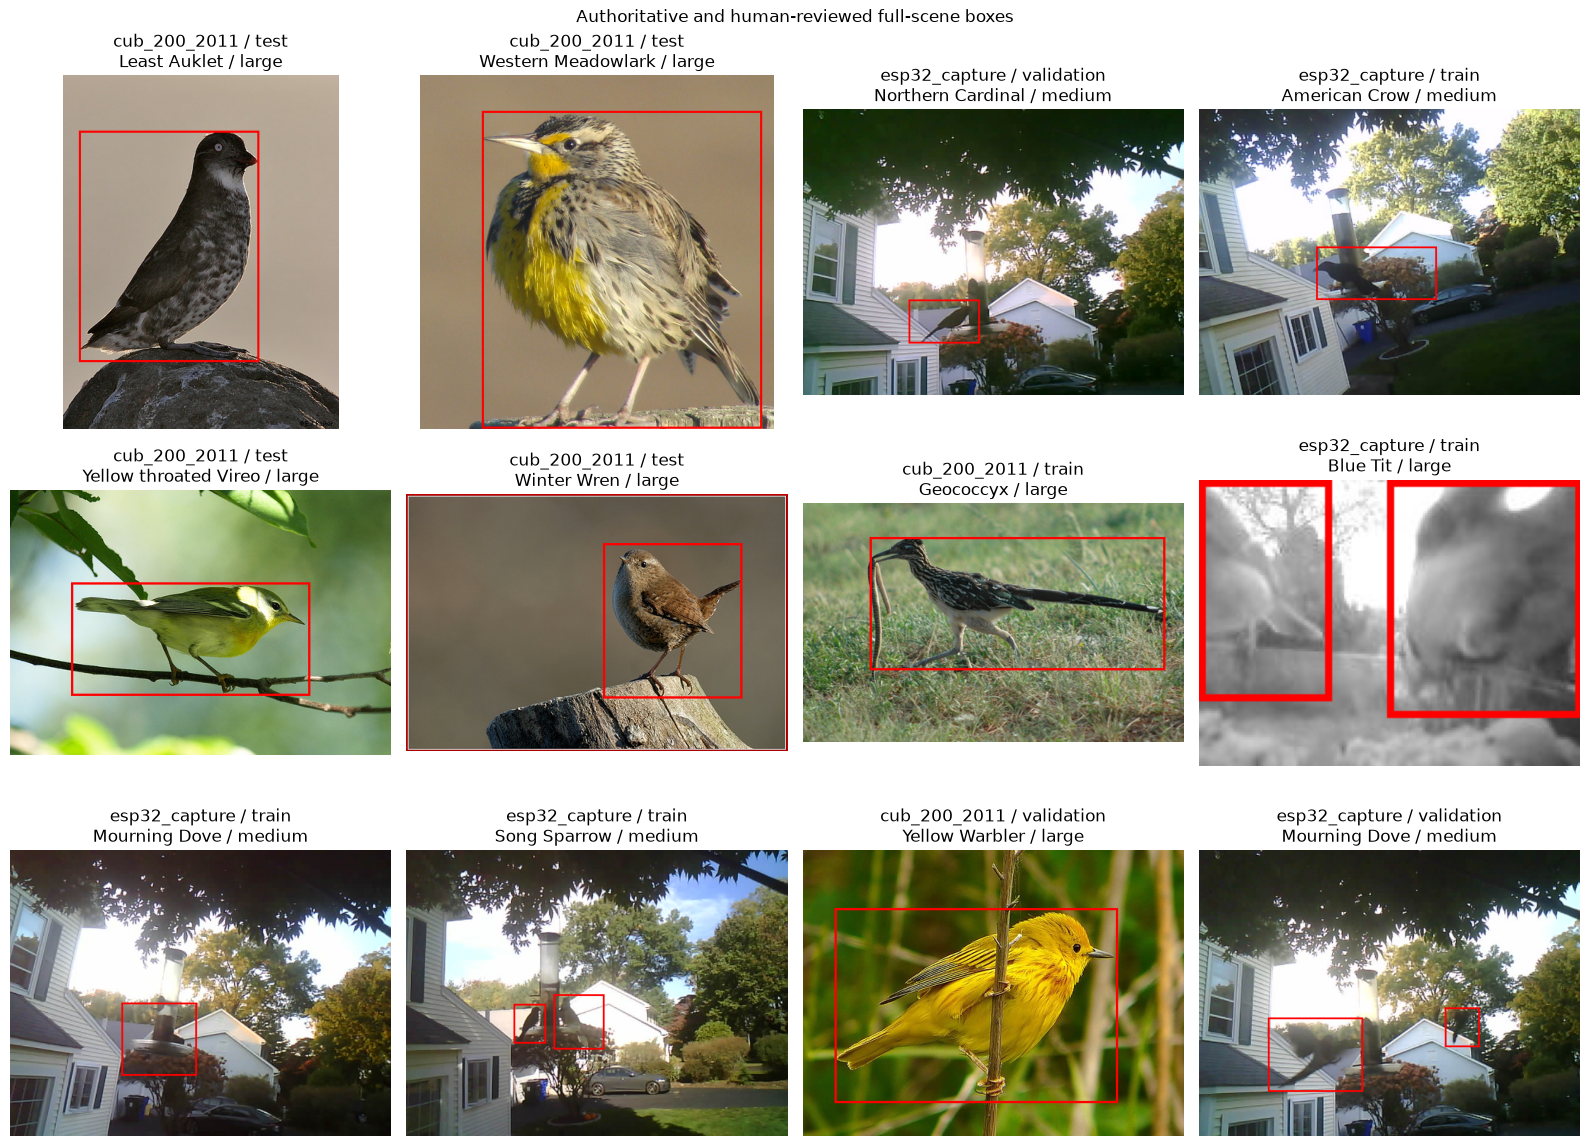

In [11]:
def show_annotations(frame: pd.DataFrame, title: str, count: int = 12) -> None:
    image_rows = frame.drop_duplicates("sample_id")
    if image_rows.empty:
        print(f"No images for {title}")
        return
    sample = image_rows.sample(min(count, len(image_rows)), random_state=SEED)
    columns = 4
    rows = math.ceil(len(sample) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows))
    axes = np.atleast_1d(axes).reshape(-1)
    for axis, image_row in zip(axes, sample.itertuples(index=False)):
        path = Path(image_row.image_path)
        with Image.open(path) as source:
            image = source.convert("RGB")
        draw = ImageDraw.Draw(image)
        boxes = frame.loc[
            frame["sample_id"].eq(image_row.sample_id) & frame["review_state"].eq("boxed")
        ]
        for box in boxes.itertuples(index=False):
            draw.rectangle((box.xmin, box.ymin, box.xmax, box.ymax), outline="red", width=3)
        axis.imshow(image)
        axis.set_title(
            f"{image_row.source_dataset} / {image_row.model_split}\n"
            f"{image_row.species_name or 'bird'} / {image_row.bird_size}"
        )
        axis.axis("off")
    for axis in axes[len(sample):]:
        axis.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


if not QUICK_RUN:
    show_annotations(
        joined_annotations.loc[
            ~joined_annotations["annotation_trust"].eq("provisional_filter_only")
            & joined_annotations["review_state"].eq("boxed")
        ],
        "Authoritative and human-reviewed full-scene boxes",
    )

## 12. Build source-weighted training phases

Phase A learns clean localization from CUB and verified iNaturalist boxes. Phase B contains all
ESP32 training images and a deterministic clean-data replay subset targeting 80% ESP32,
18% CUB, and 2% verified iNaturalist by image count.

In [12]:
def image_level_rows(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.sort_values("annotation_id").drop_duplicates("sample_id").copy()


def select_phase_rows() -> dict[str, pd.DataFrame]:
    accepted = joined_annotations.loc[
        ~joined_annotations["annotation_trust"].eq("provisional_filter_only")
        & joined_annotations["review_state"].isin(["boxed", "no_bird"])
    ].copy()
    images = image_level_rows(accepted)

    phase_a_train_ids = images.loc[
        images["model_split"].eq("train")
        & images["source_dataset"].isin(["cub_200_2011", "inaturalist"])
        & images["eligible_for_training"], "sample_id"
    ]
    phase_a_val_ids = images.loc[
        images["model_split"].eq("validation")
        & images["source_dataset"].isin(["cub_200_2011", "inaturalist"]), "sample_id"
    ]

    esp_train = images.loc[
        images["source_dataset"].eq("esp32_capture") & images["model_split"].eq("train")
    ]
    cub_pool = images.loc[
        images["source_dataset"].eq("cub_200_2011") & images["model_split"].eq("train")
    ]
    inat_pool = images.loc[
        images["source_dataset"].eq("inaturalist")
        & images["model_split"].eq("train")
        & images["eligible_for_training"]
    ]
    total_target = math.ceil(len(esp_train) / PHASE_B_SOURCE_WEIGHTS["esp32_capture"])
    cub_count = min(len(cub_pool), round(total_target * PHASE_B_SOURCE_WEIGHTS["cub_200_2011"]))
    inat_count = min(len(inat_pool), round(total_target * PHASE_B_SOURCE_WEIGHTS["inaturalist"]))
    phase_b_images = pd.concat([
        esp_train,
        cub_pool.sample(cub_count, random_state=SEED),
        inat_pool.sample(inat_count, random_state=SEED),
    ], ignore_index=True)
    phase_b_val_ids = images.loc[
        images["source_dataset"].eq("esp32_capture") & images["model_split"].eq("validation"),
        "sample_id",
    ]
    esp_test_ids = images.loc[
        images["source_dataset"].eq("esp32_capture") & images["model_split"].eq("test"),
        "sample_id",
    ]

    rng = np.random.default_rng(SEED)
    calibration_parts = []
    calibration_images = esp_train.copy()
    calibration_images["resolution"] = (
        calibration_images["width_px"].astype(int).astype(str) + "x"
        + calibration_images["height_px"].astype(int).astype(str)
    )
    calibration_images["presence"] = np.where(
        calibration_images["review_state"].eq("boxed"), "bird", "no_bird"
    )
    per_stratum = max(1, REPRESENTATIVE_ESP32_IMAGES // max(
        1, calibration_images.groupby(["resolution", "presence"]).ngroups
    ))
    for _, group in calibration_images.groupby(["resolution", "presence"]):
        calibration_parts.append(group.sample(min(per_stratum, len(group)), random_state=SEED))
    calibration = pd.concat(calibration_parts, ignore_index=True).drop_duplicates("sample_id")
    if len(calibration) < REPRESENTATIVE_ESP32_IMAGES:
        remaining = calibration_images.loc[~calibration_images["sample_id"].isin(calibration["sample_id"])]
        if len(remaining):
            order = rng.permutation(len(remaining))[: REPRESENTATIVE_ESP32_IMAGES - len(calibration)]
            calibration = pd.concat([calibration, remaining.iloc[order]], ignore_index=True)

    id_sets = {
        "phase_a_train": set(phase_a_train_ids),
        "phase_a_validation": set(phase_a_val_ids),
        "phase_b_train": set(phase_b_images["sample_id"]),
        "phase_b_validation": set(phase_b_val_ids),
        "esp32_test": set(esp_test_ids),
        "esp32_calibration": set(calibration["sample_id"]),
    }
    return {
        name: accepted.loc[accepted["sample_id"].isin(ids)].copy()
        for name, ids in id_sets.items()
    }


PHASE_ROWS = select_phase_rows()
phase_summary = pd.concat([
    image_level_rows(frame).groupby("source_dataset").size().rename("images").reset_index()
    .assign(dataset=name)
    for name, frame in PHASE_ROWS.items()
], ignore_index=True)
display(phase_summary[["dataset", "source_dataset", "images"]])

,dataset,source_dataset,images
0,phase_a_train,cub_200_2011,5194
1,phase_a_train,inaturalist,100
2,phase_a_validation,cub_200_2011,800
3,phase_a_validation,inaturalist,97
4,phase_b_train,cub_200_2011,1223
5,phase_b_train,esp32_capture,5436
6,phase_b_train,inaturalist,100
7,phase_b_validation,esp32_capture,621
8,esp32_test,esp32_capture,312
9,esp32_calibration,esp32_capture,500


## 13. Export YOLO and Pascal VOC datasets

Set `EXPORT_TRAINING_DATASETS=True` and rerun this section before training. Staging first tries
symbolic links, then hard links, then copies. It never modifies source images.

In [13]:
def stage_file(source: Path, target: Path, mode: str = STAGING_MODE) -> str:
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() or target.is_symlink():
        return "existing"
    attempts = ("symlink", "hardlink", "copy") if mode == "auto" else (mode,)
    errors = []
    for attempt in attempts:
        try:
            if attempt == "symlink":
                target.symlink_to(source)
            elif attempt == "hardlink":
                os.link(source, target)
            elif attempt == "copy":
                shutil.copy2(source, target)
            else:
                raise ValueError(f"Unknown staging mode: {attempt}")
            return attempt
        except OSError as error:
            errors.append(f"{attempt}: {error}")
    raise OSError(f"Could not stage {source} -> {target}: {'; '.join(errors)}")


def grouped_images_and_boxes(frame: pd.DataFrame) -> Iterator[tuple[pd.Series, pd.DataFrame]]:
    for _, group in frame.groupby("sample_id", sort=True):
        yield group.iloc[0], group.loc[group["review_state"].eq("boxed")]


def export_yolo_split(frame: pd.DataFrame, root: Path, split: str) -> pd.DataFrame:
    records = []
    for image_row, boxes in grouped_images_and_boxes(frame):
        source = Path(image_row["image_path"])
        suffix = source.suffix.lower() or ".jpg"
        stem = safe_slug(image_row["sample_id"])
        target_image = root / "images" / split / f"{stem}{suffix}"
        target_label = root / "labels" / split / f"{stem}.txt"
        method = stage_file(source, target_image)
        target_label.parent.mkdir(parents=True, exist_ok=True)
        lines = []
        width, height = float(image_row["width_px"]), float(image_row["height_px"])
        for box in boxes.itertuples(index=False):
            center_x = ((float(box.xmin) + float(box.xmax)) / 2) / width
            center_y = ((float(box.ymin) + float(box.ymax)) / 2) / height
            box_width = (float(box.xmax) - float(box.xmin)) / width
            box_height = (float(box.ymax) - float(box.ymin)) / height
            values = [center_x, center_y, box_width, box_height]
            if not all(0 <= value <= 1 for value in values):
                raise ValueError(f"Non-normalized YOLO box for {image_row['sample_id']}: {values}")
            lines.append("0 " + " ".join(f"{value:.8f}" for value in values))
        target_label.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
        records.append({
            "sample_id": image_row["sample_id"], "source_path": str(source),
            "staged_path": str(target_image), "label_path": str(target_label),
            "staging_method": method, "box_count": len(lines), "split": split,
        })
    return pd.DataFrame(records)


def write_yolo_yaml(root: Path, name: str, validation_path: str = "images/validation") -> Path:
    config = {
        "path": str(root.resolve()),
        "train": "images/train",
        "val": validation_path,
        "test": "images/test" if (root / "images" / "test").is_dir() else "",
        "names": {0: "bird"},
    }
    path = root / f"{name}.yaml"
    path.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
    return path


def write_pascal_voc(frame: pd.DataFrame, root: Path, split: str) -> None:
    import xml.etree.ElementTree as ET
    annotations_dir = root / "Annotations" / split
    images_dir = root / "JPEGImages" / split
    annotations_dir.mkdir(parents=True, exist_ok=True)
    images_dir.mkdir(parents=True, exist_ok=True)
    for image_row, boxes in grouped_images_and_boxes(frame):
        source = Path(image_row["image_path"])
        stem = safe_slug(image_row["sample_id"])
        suffix = source.suffix.lower() or ".jpg"
        target_image = images_dir / f"{stem}{suffix}"
        stage_file(source, target_image)
        annotation = ET.Element("annotation")
        ET.SubElement(annotation, "filename").text = target_image.name
        size = ET.SubElement(annotation, "size")
        ET.SubElement(size, "width").text = str(int(image_row["width_px"]))
        ET.SubElement(size, "height").text = str(int(image_row["height_px"]))
        ET.SubElement(size, "depth").text = "3"
        for box in boxes.itertuples(index=False):
            obj = ET.SubElement(annotation, "object")
            ET.SubElement(obj, "name").text = "bird"
            bounds = ET.SubElement(obj, "bndbox")
            ET.SubElement(bounds, "xmin").text = str(max(0, int(math.floor(box.xmin))))
            ET.SubElement(bounds, "ymin").text = str(max(0, int(math.floor(box.ymin))))
            ET.SubElement(bounds, "xmax").text = str(min(int(image_row["width_px"]), int(math.ceil(box.xmax))))
            ET.SubElement(bounds, "ymax").text = str(min(int(image_row["height_px"]), int(math.ceil(box.ymax))))
        ET.ElementTree(annotation).write(
            annotations_dir / f"{stem}.xml", encoding="utf-8", xml_declaration=True
        )


DATASET_ROOT = RUN_DIR / "datasets"
YOLO_CONFIGS: dict[str, Path] = {}
if EXPORT_TRAINING_DATASETS:
    phase_a_root = DATASET_ROOT / "yolo_phase_a"
    phase_b_root = DATASET_ROOT / "yolo_phase_b"
    calibration_root = DATASET_ROOT / "yolo_esp32_calibration"

    manifests = []
    manifests.append(export_yolo_split(PHASE_ROWS["phase_a_train"], phase_a_root, "train"))
    manifests.append(export_yolo_split(PHASE_ROWS["phase_a_validation"], phase_a_root, "validation"))
    manifests.append(export_yolo_split(PHASE_ROWS["phase_b_train"], phase_b_root, "train"))
    manifests.append(export_yolo_split(PHASE_ROWS["phase_b_validation"], phase_b_root, "validation"))
    manifests.append(export_yolo_split(PHASE_ROWS["esp32_test"], phase_b_root, "test"))
    manifests.append(export_yolo_split(PHASE_ROWS["esp32_calibration"], calibration_root, "train"))

    YOLO_CONFIGS = {
        "phase_a": write_yolo_yaml(phase_a_root, "bird_phase_a"),
        "phase_b": write_yolo_yaml(phase_b_root, "bird_phase_b"),
        # Ultralytics export calibrates from the YAML validation split by default.
        "calibration": write_yolo_yaml(
            calibration_root, "esp32_calibration", validation_path="images/train"
        ),
    }
    pd.concat(manifests, ignore_index=True).to_csv(RUN_DIR / "staged_images.csv", index=False)

    voc_root = DATASET_ROOT / "pascal_voc"
    for split_name, key in (
        ("train", "phase_b_train"),
        ("validation", "phase_b_validation"),
        ("test", "esp32_test"),
        ("calibration", "esp32_calibration"),
    ):
        write_pascal_voc(PHASE_ROWS[key], voc_root, split_name)
    print("Exported detector datasets to", DATASET_ROOT)
else:
    print("Dataset export is disabled. Set EXPORT_TRAINING_DATASETS=True before training.")

Exported detector datasets to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/datasets


## 14. Detection metrics focused on small-bird recall

Predictions use the canonical pixel-coordinate schema. Threshold selection occurs on ESP32
validation data. The selected threshold is then frozen before the final ESP32 test evaluation.

In [14]:
def box_iou(a: Sequence[float], b: Sequence[float]) -> float:
    left, top = max(a[0], b[0]), max(a[1], b[1])
    right, bottom = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0.0, right - left) * max(0.0, bottom - top)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def evaluate_predictions(
    ground_truth: pd.DataFrame,
    predictions: pd.DataFrame,
    confidence_threshold: float,
    iou_threshold: float = IOU_THRESHOLD,
) -> dict[str, Any]:
    image_rows = image_level_rows(ground_truth)
    ground_truth_boxes = ground_truth.loc[ground_truth["review_state"].eq("boxed")].copy()
    ground_truth_boxes["projected_area"] = projected_box_area(ground_truth_boxes)
    selected = predictions.loc[predictions["score"].ge(confidence_threshold)].copy()

    true_positives = false_positives = false_negatives = small_tp = small_fn = 0
    negative_images = int((~image_rows["review_state"].eq("boxed")).sum())
    false_positives_on_negative_images = 0
    matches = []
    for sample_id in image_rows["sample_id"]:
        gt_rows = ground_truth_boxes.loc[ground_truth_boxes["sample_id"].eq(sample_id)]
        pred_rows = selected.loc[selected["sample_id"].eq(sample_id)].sort_values("score", ascending=False)
        matched_gt: set[int] = set()
        for prediction in pred_rows.itertuples(index=False):
            best_index = None
            best_iou = 0.0
            for gt_index, gt in gt_rows.iterrows():
                if gt_index in matched_gt:
                    continue
                iou = box_iou(
                    (prediction.xmin, prediction.ymin, prediction.xmax, prediction.ymax),
                    (gt.xmin, gt.ymin, gt.xmax, gt.ymax),
                )
                if iou > best_iou:
                    best_iou, best_index = iou, gt_index
            if best_index is not None and best_iou >= iou_threshold:
                matched_gt.add(best_index)
                true_positives += 1
                is_small = ground_truth_boxes.loc[best_index, "projected_area"] < SMALL_BIRD_AREA_PX2
                small_tp += int(is_small)
                matches.append({"sample_id": sample_id, "score": prediction.score, "iou": best_iou})
            else:
                false_positives += 1
                if gt_rows.empty:
                    false_positives_on_negative_images += 1
        unmatched = gt_rows.loc[~gt_rows.index.isin(matched_gt)]
        false_negatives += len(unmatched)
        small_fn += int((unmatched["projected_area"] < SMALL_BIRD_AREA_PX2).sum())

    precision = true_positives / max(1, true_positives + false_positives)
    recall = true_positives / max(1, true_positives + false_negatives)
    beta2 = 4.0
    f2 = (1 + beta2) * precision * recall / max(1e-12, beta2 * precision + recall)
    small_recall = small_tp / max(1, small_tp + small_fn)
    return {
        "confidence_threshold": confidence_threshold,
        "iou_threshold": iou_threshold,
        "true_positives": true_positives,
        "false_positives": false_positives,
        "false_negatives": false_negatives,
        "precision": precision,
        "recall": recall,
        "f2": f2,
        "small_bird_recall": small_recall,
        "negative_images": negative_images,
        "false_positives_on_negative_images": false_positives_on_negative_images,
        "false_positives_per_negative_image": false_positives_on_negative_images / max(1, negative_images),
        "mean_matched_iou": float(pd.DataFrame(matches)["iou"].mean()) if matches else 0.0,
    }


def select_recall_first_threshold(ground_truth: pd.DataFrame, predictions: pd.DataFrame) -> tuple[float, pd.DataFrame]:
    sweep = pd.DataFrame([
        evaluate_predictions(ground_truth, predictions, threshold)
        for threshold in CONFIDENCE_GRID
    ])
    feasible = sweep.loc[
        sweep["false_positives_per_negative_image"].le(MAX_FALSE_POSITIVES_PER_NEGATIVE_IMAGE)
    ]
    candidates = feasible if len(feasible) else sweep
    best = candidates.sort_values(
        ["small_bird_recall", "recall", "f2", "precision", "confidence_threshold"],
        ascending=[False, False, False, False, True],
    ).iloc[0]
    return float(best["confidence_threshold"]), sweep

## 15. Train YOLO26n from COCO-pretrained weights

Required WSL environment (example):

```bash
python3.12 -m venv ~/.venvs/bird-yolo26
source ~/.venvs/bird-yolo26/bin/activate
python -m pip install --upgrade pip
python -m pip install ultralytics pandas pillow matplotlib pyyaml jupyter
```

Phase A trains clean localization. Phase B fine-tunes with an ESP32-heavy dataset and lower
learning rate. The final ten epochs disable mosaic through `close_mosaic=10`.

In [15]:
def train_yolo_with_batch_fallback(model, *, preferred_batch: int, fallback_batch: int, **kwargs):
    try:
        return model.train(batch=preferred_batch, **kwargs)
    except RuntimeError as error:
        if "out of memory" not in str(error).casefold() or preferred_batch == fallback_batch:
            raise
        print(f"CUDA OOM at batch {preferred_batch}; retrying with batch {fallback_batch}")
        try:
            import torch
            torch.cuda.empty_cache()
        except Exception:
            pass
        return model.train(batch=fallback_batch, **kwargs)


YOLO_RESULTS: dict[str, Any] = {}
if RUN_YOLO_TRAINING:
    if not EXPORT_TRAINING_DATASETS or not YOLO_CONFIGS:
        raise RuntimeError("Export datasets first by setting EXPORT_TRAINING_DATASETS=True")
    from ultralytics import YOLO

    yolo_project = RUN_DIR / "yolo"
    clean_model = YOLO("yolo26n.pt")
    YOLO_RESULTS["phase_a"] = train_yolo_with_batch_fallback(
        clean_model,
        preferred_batch=YOLO_BATCH_SIZE,
        fallback_batch=YOLO_BATCH_FALLBACK,
        data=str(YOLO_CONFIGS["phase_a"]),
        epochs=YOLO_CLEAN_EPOCHS,
        imgsz=IMAGE_SIZE,
        patience=YOLO_PATIENCE,
        device=0,
        workers=NUM_WORKERS,
        project=str(yolo_project),
        name="phase_a_clean_localization",
        exist_ok=True,
        pretrained=True,
        amp=True,
        deterministic=True,
        seed=SEED,
        save_period=1,
        cache=False,
        degrees=3.0,
        translate=0.10,
        scale=0.35,
        fliplr=0.5,
        hsv_h=0.015,
        hsv_s=0.45,
        hsv_v=0.35,
        mosaic=0.7,
        mixup=0.0,
        copy_paste=0.0,
        close_mosaic=10,
    )
    phase_a_best = yolo_project / "phase_a_clean_localization" / "weights" / "best.pt"
    if not phase_a_best.is_file():
        raise FileNotFoundError(phase_a_best)

    deployment_model = YOLO(str(phase_a_best))
    YOLO_RESULTS["phase_b"] = train_yolo_with_batch_fallback(
        deployment_model,
        preferred_batch=YOLO_BATCH_SIZE,
        fallback_batch=YOLO_BATCH_FALLBACK,
        data=str(YOLO_CONFIGS["phase_b"]),
        epochs=YOLO_ESP32_EPOCHS,
        imgsz=IMAGE_SIZE,
        patience=YOLO_PATIENCE,
        device=0,
        workers=NUM_WORKERS,
        project=str(yolo_project),
        name="phase_b_esp32_finetune",
        exist_ok=True,
        amp=True,
        deterministic=True,
        seed=SEED,
        save_period=1,
        cache=False,
        optimizer="auto",
        lr0=0.001,
        degrees=2.0,
        translate=0.08,
        scale=0.25,
        fliplr=0.5,
        hsv_h=0.01,
        hsv_s=0.35,
        hsv_v=0.30,
        mosaic=0.3,
        mixup=0.0,
        copy_paste=0.0,
        close_mosaic=10,
    )
else:
    print("YOLO training is disabled.")

Ultralytics 8.4.189 🚀 Python-3.12.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/datasets/yolo_phase_a/bird_phase_a.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.45, hsv_v=0.35, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_d

## 16. YOLO prediction adapter and recall-first checkpoint selection

In [16]:
def predict_ultralytics(model_or_path: Any, annotations: pd.DataFrame, confidence_floor: float = 0.001) -> pd.DataFrame:
    from ultralytics import YOLO
    model = model_or_path if hasattr(model_or_path, "predict") else YOLO(str(model_or_path))
    images = image_level_rows(annotations)
    path_to_sample = {str(Path(row.image_path).resolve()): row.sample_id for row in images.itertuples(index=False)}
    predictions = []
    results = model.predict(
        source=images["image_path"].tolist(), imgsz=IMAGE_SIZE, conf=confidence_floor,
        iou=0.7, device=0 if str(model_or_path).endswith(".pt") else "cpu",
        verbose=False, stream=True,
    )
    for result in results:
        sample_id = path_to_sample.get(str(Path(result.path).resolve()))
        if sample_id is None:
            raise KeyError(f"Prediction path is not in evaluation manifest: {result.path}")
        boxes = result.boxes
        if boxes is None:
            continue
        for xyxy, score, class_id in zip(
            boxes.xyxy.cpu().numpy(), boxes.conf.cpu().numpy(), boxes.cls.cpu().numpy()
        ):
            if int(class_id) != 0:
                continue
            predictions.append({
                "sample_id": sample_id, "xmin": float(xyxy[0]), "ymin": float(xyxy[1]),
                "xmax": float(xyxy[2]), "ymax": float(xyxy[3]), "score": float(score),
            })
    return pd.DataFrame(predictions, columns=["sample_id", "xmin", "ymin", "xmax", "ymax", "score"])


SELECTED_YOLO_CHECKPOINT: Path | None = None
SELECTED_YOLO_THRESHOLD: float | None = None
if RUN_YOLO_CHECKPOINT_SELECTION:
    weights_dir = RUN_DIR / "yolo" / "phase_b_esp32_finetune" / "weights"
    checkpoints = sorted(weights_dir.glob("epoch*.pt"))
    if not checkpoints:
        checkpoints = [weights_dir / "best.pt"]
    validation_gt = PHASE_ROWS["phase_b_validation"]
    checkpoint_rows = []
    for checkpoint in checkpoints:
        predictions = predict_ultralytics(checkpoint, validation_gt)
        threshold, sweep = select_recall_first_threshold(validation_gt, predictions)
        best = sweep.loc[sweep["confidence_threshold"].eq(threshold)].iloc[0].to_dict()
        checkpoint_rows.append({"checkpoint": str(checkpoint), **best})
    checkpoint_table = pd.DataFrame(checkpoint_rows).sort_values(
        ["small_bird_recall", "recall", "f2", "precision"], ascending=False
    )
    checkpoint_table.to_csv(RUN_DIR / "yolo_checkpoint_selection.csv", index=False)
    selected = checkpoint_table.iloc[0]
    SELECTED_YOLO_CHECKPOINT = Path(selected["checkpoint"])
    SELECTED_YOLO_THRESHOLD = float(selected["confidence_threshold"])
    display(checkpoint_table.head(10))

,checkpoint,confidence_threshold,iou_threshold,true_positives,false_positives,false_negatives,precision,recall,f2,small_bird_recall,negative_images,false_positives_on_negative_images,false_positives_per_negative_image,mean_matched_iou
13,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.07,0.5,510.0,471.0,68.0,0.519878,0.882353,0.774370,0.872093,170.0,14.0,0.082353,0.684622
37,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.05,0.5,492.0,848.0,86.0,0.367164,0.851211,0.673604,0.872093,170.0,10.0,0.058824,0.679132
28,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.11,0.5,479.0,313.0,99.0,0.604798,0.828720,0.771585,0.860465,170.0,16.0,0.094118,0.700607
16,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.17,0.5,478.0,258.0,100.0,0.649457,0.826990,0.784121,0.860465,170.0,16.0,0.094118,0.694958
31,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.09,0.5,484.0,361.0,94.0,0.572781,0.837370,0.766551,0.848837,170.0,17.0,0.100000,0.698109
9,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.15,0.5,467.0,273.0,111.0,0.631081,0.807958,0.765072,0.848837,170.0,15.0,0.088235,0.687923
29,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.11,0.5,476.0,312.0,102.0,0.604061,0.823529,0.767742,0.837209,170.0,16.0,0.094118,0.697924
27,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.13,0.5,469.0,287.0,109.0,0.620370,0.811419,0.764342,0.837209,170.0,17.0,0.100000,0.700411
30,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.11,0.5,476.0,314.0,102.0,0.602532,0.823529,0.767247,0.825581,170.0,15.0,0.088235,0.699111
33,/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_...,0.11,0.5,474.0,323.0,104.0,0.594730,0.820069,0.762303,0.825581,170.0,14.0,0.082353,0.699163


## 17. Export YOLO26n to float and static INT8 LiteRT

LiteRT export currently runs on Linux x86-64/macOS, so execute this cell in WSL. Static INT8
uses `quantize=8` plus the ESP32-only calibration YAML. The exported files retain `.tflite`.

In [17]:
YOLO_TFLITE_MODELS: dict[str, Path] = {}
if RUN_YOLO_LITERT_EXPORT:
    def resolve_litert_artifact(export_result: Any, *, integer: bool) -> Path:
        result = Path(export_result)
        candidates = [result] if result.is_file() and result.suffix == ".tflite" else []
        search_root = result if result.is_dir() else result.parent
        candidates.extend(sorted(search_root.glob("*.tflite")))
        candidates = list(dict.fromkeys(candidates))
        integer_markers = ("int8", "integer", "quant")
        matching = [
            candidate for candidate in candidates
            if any(marker in candidate.name.casefold() for marker in integer_markers) == integer
        ]
        if not matching:
            raise FileNotFoundError(
                f"Could not resolve {'INT8' if integer else 'float'} LiteRT artifact from "
                f"{result}; candidates={candidates}"
            )
        return max(matching, key=lambda candidate: candidate.stat().st_mtime_ns)

    if SELECTED_YOLO_CHECKPOINT is None:
        default_checkpoint = RUN_DIR / "yolo" / "phase_b_esp32_finetune" / "weights" / "best.pt"
        SELECTED_YOLO_CHECKPOINT = default_checkpoint
    if not SELECTED_YOLO_CHECKPOINT.is_file():
        raise FileNotFoundError(SELECTED_YOLO_CHECKPOINT)
    if "calibration" not in YOLO_CONFIGS:
        raise RuntimeError("Export the ESP32 calibration dataset before INT8 export")
    if not sys.platform.startswith("linux"):
        raise RuntimeError("Ultralytics LiteRT export must be run in Linux x86-64/WSL or macOS")

    from ultralytics import YOLO
    export_model = YOLO(str(SELECTED_YOLO_CHECKPOINT))
    float_export_result = export_model.export(
        format="litert", imgsz=IMAGE_SIZE, batch=1, device="cpu"
    )
    float_output = resolve_litert_artifact(float_export_result, integer=False)
    int8_export_result = export_model.export(
        format="litert", imgsz=IMAGE_SIZE, batch=1, device="cpu",
        quantize=8, data=str(YOLO_CONFIGS["calibration"]), fraction=1.0,
    )
    int8_output = resolve_litert_artifact(int8_export_result, integer=True)
    export_dir = RUN_DIR / "exports" / "yolo26n"
    export_dir.mkdir(parents=True, exist_ok=True)
    YOLO_TFLITE_MODELS = {
        "float": export_dir / "bird_detector_yolo26n_float32.tflite",
        "int8": export_dir / "bird_detector_yolo26n_int8.tflite",
    }
    shutil.copy2(float_output, YOLO_TFLITE_MODELS["float"])
    shutil.copy2(int8_output, YOLO_TFLITE_MODELS["int8"])
    print(YOLO_TFLITE_MODELS)
else:
    print("YOLO LiteRT export is disabled.")

Ultralytics 8.4.189 🚀 Python-3.12.15 torch-2.14.1+cu130 CPU (12th Gen Intel Core i7-12700H)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 2.2 GFLOPs

PyTorch: starting from '/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/yolo/phase_b_esp32_finetune/weights/epoch20.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 5, 3549) (24.8 MB)
requirements: Ultralytics requirements ['litert-torch>=0.10.0', 'ai-edge-litert>=2.3.0'] not found, attempting AutoUpdate...
INFO: pip is looking at multiple versions of anyio to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/977.1 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 977.1/977.1 kB 24.7 MB/s 

I0000 00:00:1792989570.391559    2705 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W1026 00:39:31.525000 2705 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (45 outputs left out)

(00:00) [ DONE] Write Model to 
/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T0
12939Z/yolo/phase_b_esp32_finetune/weights/epoch20_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/home/joe/venvs/yolo/lib/python3.12/site-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
Applying Transformations to tensors:: 100%|███████████████████████████████████████| 656/656 [00:00<00:00, 45217.15it/s]


Model name: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/yolo/phase_b_esp32_finetune/weights/epoch20_int8.tflite
Original model size: 9.38 MiB
Quantized model size: 2.75 MiB
Quantization Ratio: 0.29 (3.4x smaller)
Total time: 128.47 ms
LiteRT: export success ✅ 138.7s, saved as '/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/yolo/phase_b_esp32_finetune/weights/epoch20_int8.tflite' (2.8 MB)

Export complete (138.9s)
Results saved to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/yolo/phase_b_esp32_finetune/weights/epoch20_int8.tflite
Predict:         yolo predict task=detect model=/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/yolo/phase_b_esp32_finetune/weights/epoch20_int8.tflite imgsz=416

## 18. Continue in plain Keras (Model Maker removed)

The old EfficientDet-Lite1 cells depended on the abandoned `tflite-model-maker` package
and have been removed. Continue with:

**`train_bird_detector_keras_tflite_continuation.ipynb`**

That notebook is restartable and reads this run's persisted artifacts from disk. It does
not require any in-memory variables from this notebook and does not rerun manifest joining,
dataset staging, YOLO training, or YOLO export. It automatically chooses the newest
completed run (currently expected to be `bird_detector_20261026T012939Z`) and performs the
remaining Keras training, full-integer conversion, validation/test evaluation, benchmark
helper creation, and ESP32 C++ array generation.

The previous execution reached only the package-install cell; no EfficientDet checkpoint
exists to import. The reusable artifacts are the completed manifest, Pascal VOC splits,
calibration frames, YOLO checkpoints, and YOLO TFLite exports.
